# Fitur Unik: Grad-CAM dan Confidence Threshold


## 0. Setup, Konfigurasi & Versi Library

In [4]:
!unzip -q dataset.zip -d dataset

import os, json, random, hashlib, sys, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from PIL import Image

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

DATA_DIR = "dataset"
IMG_SIZE = 128
BATCH_SIZE = 32
EPOCHS = 20
LR = 1e-3
EXTS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

TARGET_ACC = 0.98           # akurasi minimum pada prediksi yang DITERIMA (dipilih dari data validasi)
MIN_THRESHOLD = 0.70        # batas bawah ambang agar penolakan input asing tetap bermakna
MODEL_PATH = "models/best_model.keras"
CLASSES_PATH = "models/class_names.json"

os.makedirs("outputs", exist_ok=True)

import sklearn, matplotlib
print("Python        :", sys.version.split()[0], "|", platform.platform())
print("TensorFlow    :", tf.__version__)
print("Keras         :", keras.__version__)
print("scikit-learn  :", sklearn.__version__)
print("pandas        :", pd.__version__, "| numpy:", np.__version__)
print("matplotlib    :", matplotlib.__version__, "| Pillow:", Image.__version__)
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    print("GPU           :", tf.config.experimental.get_device_details(gpus[0]).get("device_name", "GPU"))
else:
    print("GPU           : tidak ada (CPU)")

replace dataset/dataset/overripe/musa-acuminata-mold-e18a9afb-1d0a-11ec-96d8-d8c4975e38aa_jpg.rf.0f578f0960e7304cdce77faeb584c334.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: Python        : 3.13.18 | Linux-6.6.159+-x86_64-with-glibc2.39
TensorFlow    : 2.21.0
Keras         : 3.13.2
scikit-learn  : 1.6.1
pandas        : 2.2.3 | numpy: 2.4.6
matplotlib    : 3.10.0 | Pillow: 11.3.0
GPU           : tidak ada (CPU)


## 1. Fungsi Inferensi, Grad-CAM, dan Keputusan Threshold
Sel berikut berisi isi berkas `inference_utils.py` (berkas yang sama dipakai aplikasi demo, sehingga perilaku di notebook dan di aplikasi identik).

In [2]:
import json
import os

import numpy as np
import tensorflow as tf
from tensorflow import keras


def load_assets(model_path, classes_path, config_path=None, default_threshold=0.70):
    model = keras.models.load_model(model_path)
    with open(classes_path) as f:
        meta = json.load(f)
    threshold = default_threshold
    if config_path and os.path.exists(config_path):
        with open(config_path) as f:
            threshold = float(json.load(f).get("threshold", default_threshold))
    return model, meta["class_names"], meta["img_size"], threshold


def to_tensor(image, size):
    if isinstance(image, str):
        img = tf.io.decode_image(tf.io.read_file(image), channels=3, expand_animations=False)
    else:
        arr = np.asarray(image)
        if arr.ndim == 2:                      # grayscale -> RGB
            arr = np.stack([arr] * 3, axis=-1)
        arr = arr[..., :3]                     # buang kanal alpha bila ada
        img = tf.convert_to_tensor(arr)
    img = tf.image.resize(img, (size, size))
    return tf.cast(img, tf.float32) / 255.0


def decide(probs, class_names, threshold):
    k = int(np.argmax(probs))
    conf = float(probs[k])
    return class_names[k], conf, conf >= threshold


def find_target_layer(model):
    for layer in reversed(model.layers):
        if isinstance(layer, keras.layers.ReLU):
            return layer.name
    for layer in reversed(model.layers):
        if isinstance(layer, keras.layers.Conv2D):
            return layer.name
    return None


def make_gradcam(model, x, class_index=None, layer_name=None):
    target = layer_name or find_target_layer(model)
    if target is None:
        raise ValueError("Model tidak punya lapisan konvolusi; Grad-CAM hanya untuk CNN.")
    with tf.GradientTape() as tape:
        h = tf.convert_to_tensor(x)[None, ...]
        conv_out = None
        for layer in model.layers:
            h = layer(h, training=False)
            if layer.name == target:
                conv_out = h
        if class_index is None:
            class_index = int(tf.argmax(h[0]))
        score = h[:, class_index]
    grads = tape.gradient(score, conv_out)
    weights = tf.reduce_mean(grads, axis=(1, 2))                       # (1, C)
    cam = tf.reduce_sum(conv_out * weights[:, None, None, :], axis=-1)[0]
    cam = tf.nn.relu(cam)
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    cam = tf.image.resize(cam[..., None], (x.shape[0], x.shape[1]))[..., 0]
    return cam.numpy()


def overlay(x, heatmap, alpha=0.4):
    import matplotlib
    heat = matplotlib.colormaps["jet"](heatmap)[..., :3]
    out = (1 - alpha) * np.asarray(x) + alpha * heat
    return (np.clip(out, 0, 1) * 255).astype("uint8")

## 2. Memuat Model & Membentuk Ulang Data Uji/Validasi

In [6]:
model, class_names, IMG_SIZE, _ = load_assets(MODEL_PATH, CLASSES_PATH)
NUM_CLASSES = len(class_names)
print("Kelas:", class_names, "| ukuran gambar:", IMG_SIZE)
assert find_target_layer(model) is not None, (
    "Model ini tidak punya lapisan konvolusi (kemungkinan MLP). Grad-CAM butuh CNN: "
    "ubah MODEL_PATH ke model CNN terbaik, mis. 'models/cnn_aug_adam.keras' atau 'models/cnn_adam.keras'.")

def scan_dataset(data_dir):
    rows = []
    for root, _, files in os.walk(data_dir):
        for f in files:
            if f.lower().endswith(EXTS):
                raw = os.path.basename(root).strip().lower()
                rows.append((os.path.join(root, f), CLASS_MAP.get(raw, raw)))
    return pd.DataFrame(rows, columns=["path", "label"])

def is_valid(path):
    try:
        with Image.open(path) as im:
            im.verify()
        return True
    except Exception:
        return False

def md5(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

# Langkah identik dengan notebook utama agar pembagian data sama persis
df = scan_dataset(DATA_DIR)
if KEEP_CLASSES:
    df = df[df.label.isin(KEEP_CLASSES)]
df = df[df.path.map(is_valid)].copy()
df["hash"] = df.path.map(md5)
df = df.drop_duplicates("hash").reset_index(drop=True)
assert sorted(df.label.unique()) == sorted(class_names), "Kelas dataset tidak sama dengan class_names.json"
df["label_id"] = df.label.map({c: i for i, c in enumerate(class_names)})

train_df, tmp_df = train_test_split(df, test_size=0.30, stratify=df.label_id, random_state=SEED)
val_df, test_df = train_test_split(tmp_df, test_size=0.50, stratify=tmp_df.label_id, random_state=SEED)
val_df, test_df = val_df.reset_index(drop=True), test_df.reset_index(drop=True)
print(f"Validasi: {len(val_df)} gambar | Uji: {len(test_df)} gambar")

AUTOTUNE = tf.data.AUTOTUNE
def make_dataset(frame):
    ds = tf.data.Dataset.from_tensor_slices((frame.path.values, frame.label_id.values.astype("int32")))
    ds = ds.map(lambda p, y: (to_tensor_tf(p), y), num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

def to_tensor_tf(path):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return tf.cast(img, tf.float32) / 255.0

val_ds, test_ds = make_dataset(val_df), make_dataset(test_df)

_, test_acc = model.evaluate(test_ds, verbose=0)
print(f"\nAkurasi data uji = {test_acc:.4f}")
print("PERIKSA: angka ini harus SAMA dengan 'test_acc' model terbaik di notebook utama.")
print("Jika berbeda, pastikan DATA_DIR/CLASS_MAP/KEEP_CLASSES dan isi dataset identik dengan saat training.")

probs_val = model.predict(val_ds, verbose=0)
probs_test = model.predict(test_ds, verbose=0)
y_val, y_test = val_df.label_id.values, test_df.label_id.values
pred_val, pred_test = probs_val.argmax(1), probs_test.argmax(1)

Kelas: ['overripe', 'ripe', 'unripe'] | ukuran gambar: 128
Validasi: 110 gambar | Uji: 111 gambar

Akurasi data uji = 0.2703
PERIKSA: angka ini harus SAMA dengan 'test_acc' model terbaik di notebook utama.
Jika berbeda, pastikan DATA_DIR/CLASS_MAP/KEEP_CLASSES dan isi dataset identik dengan saat training.


## 3. Fitur Unik 1: Grad-CAM
**Apa:** Grad-CAM menghitung gradien skor kelas terhadap peta fitur lapisan konvolusi terakhir, lalu menampilkannya sebagai heatmap. Warna merah/kuning = area yang paling memengaruhi keputusan.

**Mengapa dibutuhkan:** model deep learning bersifat *black box*. Dengan Grad-CAM kita dapat memeriksa apakah model menilai kematangan dari **kulit pisang** (warna, bintik cokelat) atau justru dari latar belakang/bayangan, dan memahami penyebab salah prediksi.

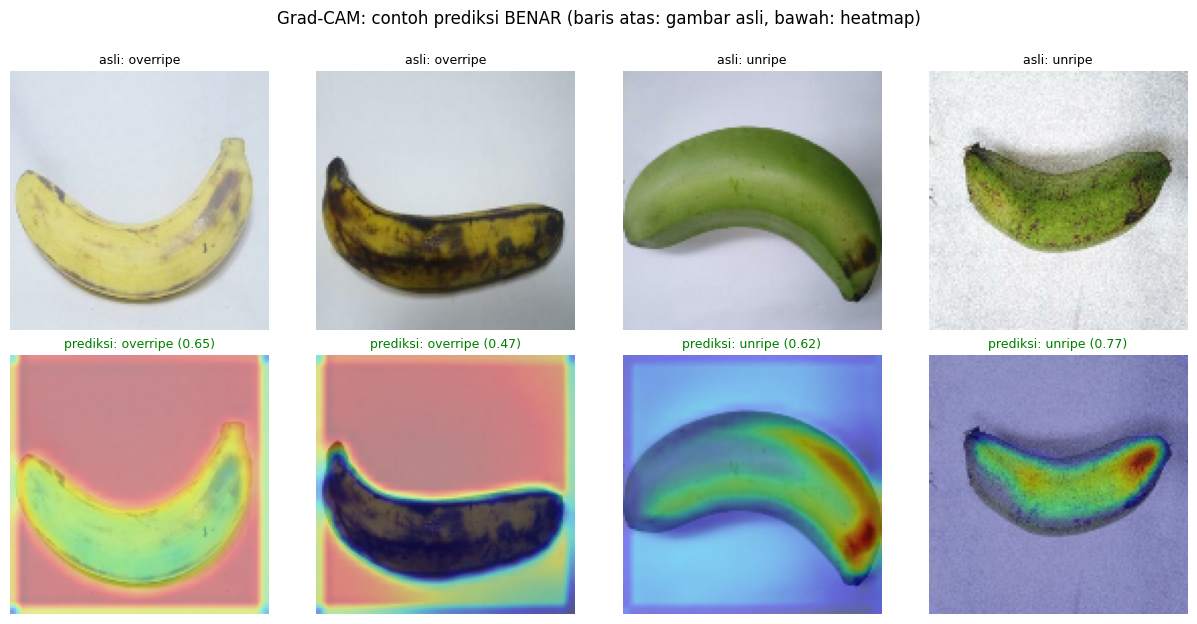

Jumlah salah prediksi pada data uji: 81


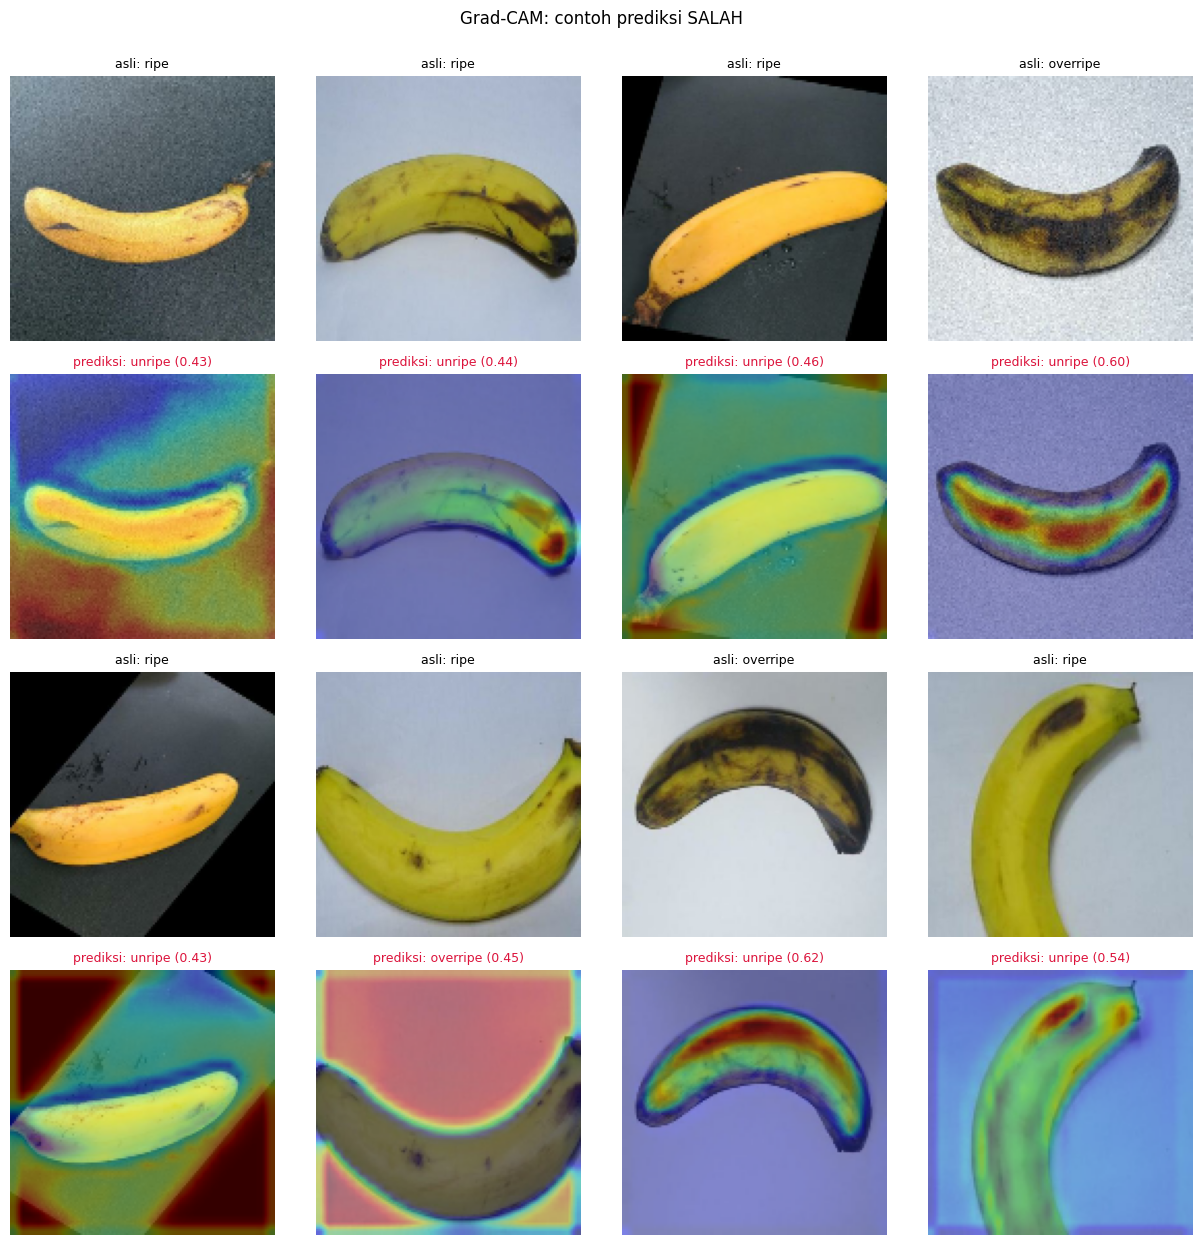

In [8]:
def plot_cam_grid(indices, title, fname, ncols=4):
    indices = list(indices)
    if not indices:
        print("(tidak ada contoh)"); return
    groups = [indices[i:i + ncols] for i in range(0, len(indices), ncols)]
    fig, axes = plt.subplots(2 * len(groups), ncols, figsize=(3.1 * ncols, 6.2 * len(groups)), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for g, grp in enumerate(groups):
        for c, idx in enumerate(grp):
            x = to_tensor(test_df.path[idx], IMG_SIZE)
            cam = make_gradcam(model, x, class_index=int(pred_test[idx]))
            axes[2 * g, c].imshow(np.asarray(x))
            axes[2 * g, c].set_title(f"asli: {class_names[y_test[idx]]}", fontsize=9)
            axes[2 * g + 1, c].imshow(overlay(x, cam))
            ok = pred_test[idx] == y_test[idx]
            axes[2 * g + 1, c].set_title(f"prediksi: {class_names[pred_test[idx]]} ({probs_test[idx].max():.2f})",
                                         fontsize=9, color="green" if ok else "crimson")
    fig.suptitle(title, y=1.0)
    plt.tight_layout(); plt.savefig(fname, dpi=150, bbox_inches="tight"); plt.show()

rng = np.random.default_rng(SEED)
correct = np.where(pred_test == y_test)[0]
picked = []
for k in range(NUM_CLASSES):                      # 2 contoh benar per kelas
    pool = [i for i in correct if y_test[i] == k]
    picked += list(rng.choice(pool, size=min(2, len(pool)), replace=False)) if pool else []
plot_cam_grid(picked, "Grad-CAM: contoh prediksi BENAR (baris atas: gambar asli, bawah: heatmap)", "outputs/gradcam_benar.png")

wrong = np.where(pred_test != y_test)[0]
print("Jumlah salah prediksi pada data uji:", len(wrong))
plot_cam_grid(wrong[:8], "Grad-CAM: contoh prediksi SALAH", "outputs/gradcam_salah.png")

### Bukti dampak Grad-CAM: uji penghapusan (*deletion test*)
Jika heatmap benar-benar menunjukkan area penting, maka **menutup area sorotan** (20% piksel dengan nilai Grad-CAM tertinggi) harus menurunkan keyakinan model **lebih besar** daripada menutup **kotak acak** seluas sama.

Jumlah gambar yang diuji: 111
                 skenario  akurasi  rata2_keyakinan_kelas_prediksi
          Tanpa penutupan   0.2703                          0.5460
Tutup area Grad-CAM (20%)   0.3423                          0.4607
   Tutup kotak acak (20%)   0.2703                          0.5217

Rata-rata penurunan keyakinan: Grad-CAM = 0.0853 | acak = 0.0243


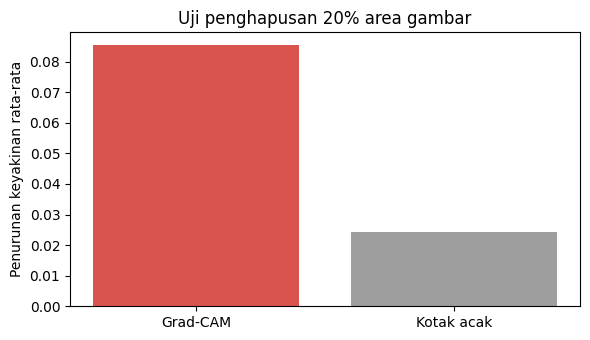

In [9]:
FRAC = 0.20
N_EVAL = min(150, len(test_df))
idxs = rng.choice(len(test_df), size=N_EVAL, replace=False)

def mask_heatmap(x, cam, frac=FRAC):
    thr = np.quantile(cam, 1 - frac)
    m = ((cam >= thr) & (cam > 0))[..., None]
    return np.where(m, 0.5, x).astype("float32")

def mask_random_square(x, frac=FRAC):
    S = x.shape[0]; side = int(round(S * np.sqrt(frac)))
    r, c = rng.integers(0, S - side + 1), rng.integers(0, S - side + 1)
    out = x.copy(); out[r:r + side, c:c + side, :] = 0.5
    return out

orig, m_cam, m_rand, yt = [], [], [], []
for i in idxs:
    x = np.asarray(to_tensor(test_df.path[i], IMG_SIZE))
    cam = make_gradcam(model, tf.convert_to_tensor(x), class_index=int(pred_test[i]))
    orig.append(x); m_cam.append(mask_heatmap(x, cam)); m_rand.append(mask_random_square(x)); yt.append(y_test[i])
yt = np.array(yt)

def stats(batch):
    p = model.predict(np.stack(batch), verbose=0)
    return p, p.argmax(1)

p0, a0 = stats(orig); p1, a1 = stats(m_cam); p2, a2 = stats(m_rand)
cls0 = p0.argmax(1)
conf0 = p0[np.arange(N_EVAL), cls0]
drop_cam = conf0 - p1[np.arange(N_EVAL), cls0]
drop_rand = conf0 - p2[np.arange(N_EVAL), cls0]

deletion = pd.DataFrame({
    "skenario": ["Tanpa penutupan", "Tutup area Grad-CAM (20%)", "Tutup kotak acak (20%)"],
    "akurasi": [(a0 == yt).mean(), (a1 == yt).mean(), (a2 == yt).mean()],
    "rata2_keyakinan_kelas_prediksi": [conf0.mean(), p1[np.arange(N_EVAL), cls0].mean(), p2[np.arange(N_EVAL), cls0].mean()],
}).round(4)
print(f"Jumlah gambar yang diuji: {N_EVAL}")
print(deletion.to_string(index=False))
print(f"\nRata-rata penurunan keyakinan: Grad-CAM = {drop_cam.mean():.4f} | acak = {drop_rand.mean():.4f}")
deletion.to_csv("outputs/gradcam_deletion_test.csv", index=False)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(["Grad-CAM", "Kotak acak"], [drop_cam.mean(), drop_rand.mean()], color=["#d9534f", "#9e9e9e"])
ax.set_ylabel("Penurunan keyakinan rata-rata"); ax.set_title("Uji penghapusan 20% area gambar")
plt.tight_layout(); plt.savefig("outputs/gradcam_deletion_test.png", dpi=150); plt.show()

## 4. Fitur Unik 2: Confidence Threshold (Penolakan Prediksi Tidak Yakin)
**Apa:** jika probabilitas tertinggi model < ambang (*threshold*), aplikasi menjawab **"TIDAK YAKIN"** dan meminta foto ulang/cek manual, bukan memaksakan jawaban.

**Mengapa dibutuhkan:** model softmax selalu memilih salah satu kelas, bahkan untuk foto yang buram, bukan pisang, atau berada di batas dua kelas (misalnya *ripe* vs *overripe*). Penolakan mengurangi risiko jawaban salah yang terlihat meyakinkan.

**Cara menentukan ambang:** dipilih dari **data validasi** (ambang terkecil yang membuat akurasi prediksi yang diterima >= `TARGET_ACC`, dengan batas bawah `MIN_THRESHOLD`), lalu dilaporkan pada **data uji**. Data uji tidak dipakai untuk memilih ambang.

Tabel pada data VALIDASI:
 threshold  coverage  akurasi_diterima  jumlah_ditolak  kesalahan_tertangkap  total_kesalahan
      0.50    0.5545            0.4590              49                    42               75
      0.55    0.4273            0.5745              63                    55               75
      0.60    0.3091            0.7059              76                    65               75
      0.65    0.2455            0.7037              83                    67               75
      0.70    0.1455            0.9375              94                    74               75
      0.75    0.0909            1.0000             100                    75               75
      0.80    0.0273            1.0000             107                    75               75
      0.85    0.0182            1.0000             108                    75               75
      0.90    0.0000               NaN             110                    75               75
      0.95    0.0000              

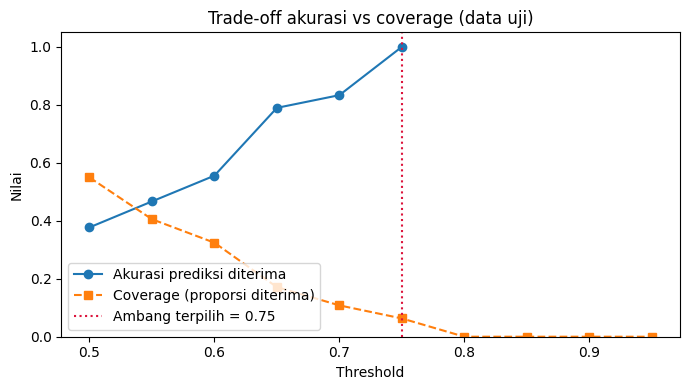

Tersimpan: models/inference_config.json


In [10]:
def coverage_table(probs, y, thresholds):
    conf, pred = probs.max(1), probs.argmax(1)
    wrong_total = int((pred != y).sum())
    rows = []
    for t in thresholds:
        keep = conf >= t
        rows.append({
            "threshold": round(float(t), 2),
            "coverage": float(keep.mean()),
            "akurasi_diterima": float((pred[keep] == y[keep]).mean()) if keep.any() else np.nan,
            "jumlah_ditolak": int((~keep).sum()),
            "kesalahan_tertangkap": int(((pred != y) & ~keep).sum()),
            "total_kesalahan": wrong_total,
        })
    return pd.DataFrame(rows)

thresholds = np.round(np.arange(0.50, 1.0, 0.05), 2)
tab_val = coverage_table(probs_val, y_val, thresholds)
ok = tab_val[(tab_val.akurasi_diterima >= TARGET_ACC) & (tab_val.threshold >= MIN_THRESHOLD)]
THRESHOLD = float(ok.threshold.min()) if len(ok) else float(max(MIN_THRESHOLD, 0.80))
print("Tabel pada data VALIDASI:"); print(tab_val.round(4).to_string(index=False))
print(f"\nAmbang terpilih (dari validasi): {THRESHOLD:.2f}")

tab_test = coverage_table(probs_test, y_test, sorted(set(thresholds) | {THRESHOLD}))
tab_test.to_csv("outputs/confidence_threshold_test.csv", index=False)
print("\nTabel pada data UJI:"); print(tab_test.round(4).to_string(index=False))

row = tab_test[tab_test.threshold == round(THRESHOLD, 2)].iloc[0]
print(f"\nRingkasan (ambang {THRESHOLD:.2f}, data uji):")
print(f"- akurasi tanpa penolakan      : {(pred_test == y_test).mean():.4f}")
print(f"- akurasi pada prediksi diterima: {row.akurasi_diterima:.4f} (coverage {row.coverage:.2%})")
print(f"- kesalahan yang berhasil dicegah: {int(row.kesalahan_tertangkap)} dari {int(row.total_kesalahan)}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(tab_test.threshold, tab_test.akurasi_diterima, "o-", label="Akurasi prediksi diterima")
ax.plot(tab_test.threshold, tab_test.coverage, "s--", label="Coverage (proporsi diterima)")
ax.axvline(THRESHOLD, color="crimson", ls=":", label=f"Ambang terpilih = {THRESHOLD:.2f}")
ax.set_xlabel("Threshold"); ax.set_ylabel("Nilai"); ax.set_ylim(0, 1.05); ax.legend(loc="lower left")
ax.set_title("Trade-off akurasi vs coverage (data uji)")
plt.tight_layout(); plt.savefig("outputs/confidence_threshold_tradeoff.png", dpi=150); plt.show()

with open("models/inference_config.json", "w") as f:
    json.dump({"threshold": THRESHOLD, "target_acc": TARGET_ACC, "chosen_on": "validation"}, f, indent=2)
print("Tersimpan: models/inference_config.json")

In [11]:
!zip -qr hasil_fitur_unik.zip models/inference_config.json outputs
from google.colab import files
files.download("hasil_fitur_unik.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 5. Ringkasan untuk Laporan
Salin angka-angka berikut dari output di atas ke laporan (bagian 5e dan 6): hasil uji penghapusan Grad-CAM, tabel coverage vs akurasi, ambang terpilih, dan persentase foto non-pisang yang ditolak.

Berkas hasil di folder `outputs/`: `gradcam_benar.png`, `gradcam_salah.png`, `gradcam_deletion_test.png/.csv`, `confidence_threshold_test.csv`, `confidence_threshold_tradeoff.png`, `uji_non_pisang.csv`.
**Unduh juga `models/inference_config.json`** (dipakai aplikasi demo) dan letakkan di folder `models` bersama `best_model.keras`.